<a href="https://colab.research.google.com/github/kartikirasane27/Deep_Learning/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "click>=8.0,<8.2"
!pip install -q tensorflow librosa soundfile SpeechRecognition jiwer tensorflow-datasets
!pip install -q gTTS
!pip install -q openai-whisper --no-deps


In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "speech_commands",
    split="train",
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Available labels:", info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


...

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/speech_commands/incomplete.R0L1Y4_0.0.3/speech_commands-validation.tfrecor…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/speech_commands/incomplete.R0L1Y4_0.0.3/speech_commands-test.tfrecord-[0-9…

Dataset speech_commands downloaded and prepared to /root/tensorflow_datasets/speech_commands/0.0.3. Subsequent calls will reuse this data.
Dataset loaded successfully!
Available labels: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes', '_silence_', '_unknown_']


In [ ]:
import numpy as np
import librosa
import tensorflow_datasets as tfds

selected_words = ["yes", "no", "up", "down"]
word_to_label = {word: i for i, word in enumerate(selected_words)}

X, y = [], []

for audio, label in tfds.as_numpy(dataset):
    word = info.features["label"].int2str(int(label))

    if word in selected_words:
        audio = audio.astype(np.float32)

        if len(audio) < 16000:
            audio = np.pad(audio, (0, 16000 - len(audio)))
        else:
            audio = audio[:16000]

        mel = librosa.feature.melspectrogram(
            y=audio, sr=16000, n_fft=400,
            hop_length=160, n_mels=40
        )

        mel = librosa.power_to_db(mel, ref=np.max)

        X.append(mel)
        y.append(word_to_label[word])

    if len(X) >= 2000:
        break

X = np.array(X, dtype=np.float32)[..., np.newaxis]
y = np.array(y, dtype=np.int32)

print("Data shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", selected_words)

Data shape: (2000, 40, 101, 1)
Labels shape: (2000,)
Classes: ['yes', 'no', 'up', 'down']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 50, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 25, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,716 (108.27 KB)

 Trainable params: 27,716 (108.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 132ms/step - accuracy: 0.2516 - loss: 1.6453 - val_accuracy: 0.2625 - val_loss: 1.3912
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.2734 - loss: 1.3872 - val_accuracy: 0.4531 - val_loss: 1.3621
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 146ms/step - accuracy: 0.3180 - loss: 1.3687 - val_accuracy: 0.5406 - val_loss: 1.3277
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.4062 - loss: 1.2768 - val_accuracy: 0.4844 - val_loss: 1.1958
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.4516 - loss: 1.1799 - val_accuracy: 0.4250 - val_loss: 1.1376
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 139ms/step - accuracy: 0.5000 - loss: 1.1246 - val_accuracy: 0.6031 - val_loss: 0.9925
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.5586 - loss: 1.0235 - val_accuracy: 0.5625 - val_loss: 0.9786
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - accuracy: 0.6172 - loss: 0.9582 - val_accuracy: 0

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Precision:", round(
    precision_score(y_test, y_pred, average="macro", zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred, average="macro", zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3],
    target_names=selected_words,
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step
Accuracy: 0.705
Precision: 0.7181
Recall: 0.7
F1-score: 0.6828

Classification Report:
              precision    recall  f1-score   support

         yes       0.74      0.82      0.78       102
          no       0.69      0.79      0.73       108
          up       0.67      0.85      0.75        95
        down       0.78      0.34      0.47        95

    accuracy                           0.70       400
   macro avg       0.72      0.70      0.68       400
weighted avg       0.72      0.70      0.69       400



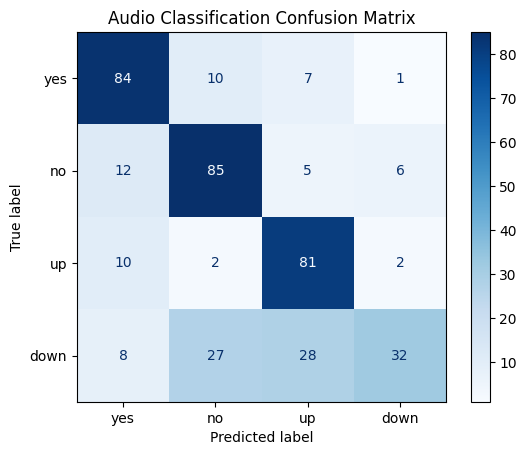

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_words
).plot(cmap="Blues", values_format="d")

plt.title("Audio Classification Confusion Matrix")
plt.show()

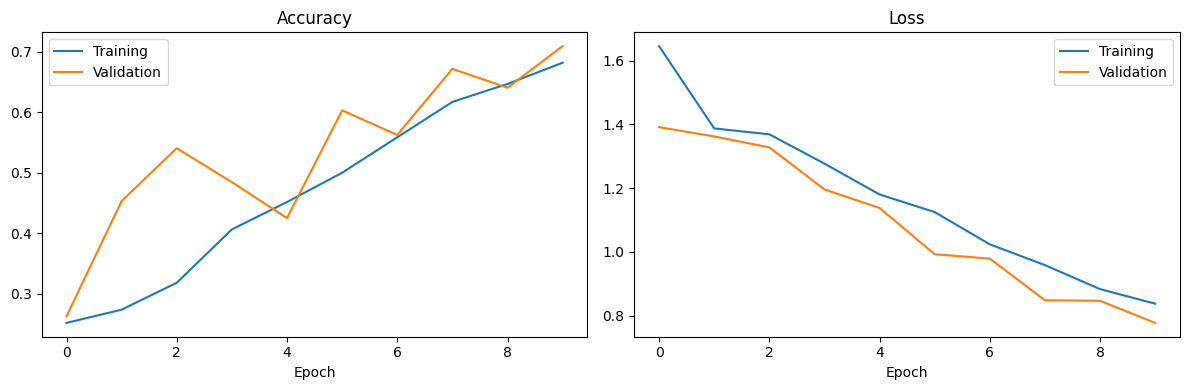

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import whisper

stt_model = whisper.load_model("base")

print("Whisper loaded successfully!")

100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 121MiB/s]


Whisper loaded successfully!


In [ ]:
from google.colab import output
from IPython.display import display, Javascript, Audio
from base64 import b64decode

def record_audio(seconds=3):
    js = Javascript("""
    async function recordAudio(seconds) {
        const stream = await navigator.mediaDevices.getUserMedia({
            audio: true
        });

        const recorder = new MediaRecorder(stream);
        const chunks = [];

        recorder.ondataavailable = event => chunks.push(event.data);

        recorder.start();

        await new Promise(resolve =>
            setTimeout(resolve, seconds * 1000)
        );

        await new Promise(resolve => {
            recorder.onstop = resolve;
            recorder.stop();
        });

        stream.getTracks().forEach(track => track.stop());

        const blob = new Blob(chunks, {type: recorder.mimeType});
        const reader = new FileReader();
        reader.readAsDataURL(blob);

        return await new Promise(resolve => {
            reader.onloadend = () =>
                resolve(reader.result.split(',')[1]);
        });
    }
    """)

    display(js)

    data = output.eval_js(f"recordAudio({seconds})")

    with open("/content/recorded_audio.webm", "wb") as f:
        f.write(b64decode(data))

    return "/content/recorded_audio.webm"

audio_file = record_audio(3)

print("Recording completed successfully!")
display(Audio(audio_file))

<IPython.core.display.Javascript object>

Recording completed successfully!


In [ ]:
result = stt_model.transcribe(audio_file)

recognized_text = result["text"].strip()

print("Recognized Speech:", recognized_text)

/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


Recognized Speech: Guys, what's the most important thing I've ever put forward?


In [ ]:
from gtts import gTTS
from IPython.display import Audio, display

if recognized_text:
    speech = gTTS(text=recognized_text, lang="en")
    speech.save("/content/generated_speech.mp3")

    display(Audio("/content/generated_speech.mp3"))
else:
    print("No speech detected. Please record again.")

In [ ]:
def classify_audio(audio_path):
    audio, sr = librosa.load(audio_path, sr=16000, mono=True)

    if len(audio) < 16000:
        audio = np.pad(audio, (0, 16000 - len(audio)))
    else:
        audio = audio[:16000]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=16000,
        n_fft=400,
        hop_length=160,
        n_mels=40
    )

    mel = librosa.power_to_db(mel, ref=np.max)
    mel = mel[np.newaxis, ..., np.newaxis]

    probabilities = model.predict(mel, verbose=0)[0]
    index = np.argmax(probabilities)

    return selected_words[index], float(probabilities[index])


def audio_classification_app():
    print("Speak one word: yes, no, up, or down.")

    path = record_audio(3)

    # Speech-to-Text
    text = stt_model.transcribe(path)["text"].strip()
    print("Recognized Speech:", text)

    # Audio Classification
    predicted_word, confidence = classify_audio(path)

    print("Predicted Class:", predicted_word)
    print("Confidence:", round(confidence * 100, 2), "%")

    # Text-to-Speech
    message = f"You said {text}. The predicted class is {predicted_word}."

    speech = gTTS(text=message, lang="en")
    speech.save("/content/result.mp3")

    display(Audio("/content/result.mp3", autoplay=False))


audio_classification_app()

Speak one word: yes, no, up, or down.


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


Recognized Speech: 


/tmp/ipykernel_1686/290365635.py:2: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(audio_path, sr=16000, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Predicted Class: no
Confidence: 47.1 %
